# Detecção espectral em grafos
**Zachary's Karate Club · SCC5882 · Marco Fidel Mayta Quispe · PhD Student · ICMC-USP**

In [1]:
from pathlib import Path
import warnings
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from scipy.sparse.linalg import eigsh
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

SEED = 42
THRESHOLD = 0.0
K_SPECTRAL = 2
K_EIGENGAP_MAX = 10
RANDOM_WALK_STEPS = 25
OUTPUTS = Path("outputs")
OUTPUTS.mkdir(parents=True, exist_ok=True)

np.random.seed(SEED)
warnings.filterwarnings("ignore", category=UserWarning)

In [2]:
def validar_matriz(A: np.ndarray) -> None:
    if A.ndim != 2 or A.shape[0] != A.shape[1]:
        raise ValueError("A matriz deve ser quadrada.")
    if not np.allclose(A, A.T):
        raise ValueError("A matriz deve ser simétrica.")
    if np.any(A < 0):
        raise ValueError("A matriz deve ter pesos não negativos.")

def comunidades_de_rotulos(rotulos: np.ndarray) -> list[set[int]]:
    rotulos = np.asarray(rotulos, dtype=int)
    return [set(np.where(rotulos == c)[0].tolist()) for c in sorted(np.unique(rotulos))]

def modularidade(G: nx.Graph, rotulos: np.ndarray) -> float:
    return float(nx.algorithms.community.quality.modularity(
        G, comunidades_de_rotulos(rotulos), weight=None
    ))

def metricas_externas(referencia: np.ndarray, rotulos: np.ndarray) -> tuple[float, float]:
    return (
        float(adjusted_rand_score(referencia, rotulos)),
        float(normalized_mutual_info_score(referencia, rotulos))
    )

def valor_cut(A: np.ndarray, rotulos: np.ndarray) -> float:
    rotulos = np.asarray(rotulos)
    grupos = np.unique(rotulos)
    if len(grupos) != 2:
        raise ValueError("O cut requer exatamente dois grupos.")
    S = np.where(rotulos == grupos[0])[0]
    T = np.where(rotulos == grupos[1])[0]
    return float(A[np.ix_(S, T)].sum())

def ratio_cut(A: np.ndarray, rotulos: np.ndarray) -> float:
    rotulos = np.asarray(rotulos)
    grupos = np.unique(rotulos)
    if len(grupos) != 2:
        raise ValueError("RatioCut requer exatamente dois grupos.")
    S = np.where(rotulos == grupos[0])[0]
    T = np.where(rotulos == grupos[1])[0]
    c = valor_cut(A, rotulos)
    return float(c * (1.0 / len(S) + 1.0 / len(T)))

def normalized_cut(A: np.ndarray, rotulos: np.ndarray) -> float:
    rotulos = np.asarray(rotulos)
    grupos = np.unique(rotulos)
    if len(grupos) != 2:
        raise ValueError("Ncut requer exatamente dois grupos.")
    graus = A.sum(axis=1)
    S = np.where(rotulos == grupos[0])[0]
    T = np.where(rotulos == grupos[1])[0]
    vol_S = float(graus[S].sum())
    vol_T = float(graus[T].sum())
    if vol_S <= 0 or vol_T <= 0:
        raise ValueError("Os volumes devem ser positivos.")
    c = valor_cut(A, rotulos)
    return float(c * (1.0 / vol_S + 1.0 / vol_T))

def rotulos_threshold(v: np.ndarray, threshold: float) -> np.ndarray:
    return (np.asarray(v) > threshold).astype(int)

def sweep_fiedler(A: np.ndarray, v2: np.ndarray) -> list[dict[str, float]]:
    valores = np.sort(np.unique(v2))
    thresholds = (valores[:-1] + valores[1:]) / 2.0
    thresholds = np.sort(np.unique(np.concatenate([thresholds, np.array([0.0])])))
    linhas = []
    for t in thresholds:
        rotulos = rotulos_threshold(v2, float(t))
        if len(np.unique(rotulos)) != 2:
            continue
        linhas.append({
            "threshold": float(t),
            "cut": valor_cut(A, rotulos),
            "ratiocut": ratio_cut(A, rotulos),
            "ncut": normalized_cut(A, rotulos),
            "n0": int(np.sum(rotulos == 0)),
            "n1": int(np.sum(rotulos == 1))
        })
    return linhas

def laplacianos(A: np.ndarray) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    validar_matriz(A)
    graus = A.sum(axis=1)
    if np.any(graus <= 0):
        raise ValueError("O grafo não pode conter vértices isolados nesta etapa.")
    D = np.diag(graus)
    L = D - A
    D_inv_sqrt = np.diag(1.0 / np.sqrt(graus))
    D_inv = np.diag(1.0 / graus)
    L_sym = np.eye(A.shape[0]) - D_inv_sqrt @ A @ D_inv_sqrt
    P = D_inv @ A
    L_rw = np.eye(A.shape[0]) - P
    return D, L, L_sym, L_rw, P

def spectral_clustering(A: np.ndarray, k: int, seed: int = SEED) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    if k < 2 or k >= A.shape[0]:
        raise ValueError("k deve estar entre 2 e n-1.")
    _, _, L_sym, _, _ = laplacianos(A)
    valores, vetores = np.linalg.eigh(L_sym)
    U = vetores[:, :k]
    normas = np.linalg.norm(U, axis=1, keepdims=True)
    T = U / np.where(normas == 0.0, 1.0, normas)
    modelo = KMeans(n_clusters=k, n_init=50, random_state=seed)
    rotulos = modelo.fit_predict(T)
    return rotulos.astype(int), T, valores

def modularity_matrix(A: np.ndarray) -> tuple[np.ndarray, np.ndarray, float]:
    validar_matriz(A)
    k = A.sum(axis=1)
    m = float(A.sum() / 2.0)
    if m <= 0:
        raise ValueError("O grafo deve conter arestas.")
    B = A - np.outer(k, k) / (2.0 * m)
    return B, k, m

def newman_leading(A: np.ndarray) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    B, _, _ = modularity_matrix(A)
    valores, vetores = np.linalg.eigh(B)
    idx = int(np.argmax(valores))
    leading = vetores[:, idx]
    rotulos = (leading >= 0.0).astype(int)
    return rotulos, valores, leading

def newman_recursivo(A: np.ndarray, tol: float = 1e-10) -> tuple[np.ndarray, list[set[int]], list[dict[str, float]]]:
    B, _, m = modularity_matrix(A)
    n = A.shape[0]
    folhas: list[set[int]] = []
    ganhos: list[dict[str, float]] = []

    def dividir(grupo: np.ndarray) -> None:
        idx = np.array(sorted(grupo.tolist()), dtype=int)
        if len(idx) <= 1:
            folhas.append(set(idx.tolist()))
            return
        Bg = B[np.ix_(idx, idx)]
        Bg_corr = Bg - np.diag(Bg.sum(axis=1))
        valores, vetores = np.linalg.eigh(Bg_corr)
        j = int(np.argmax(valores))
        if float(valores[j]) <= tol:
            folhas.append(set(idx.tolist()))
            return
        s = np.where(vetores[:, j] >= 0.0, 1.0, -1.0)
        if np.all(s > 0) or np.all(s < 0):
            folhas.append(set(idx.tolist()))
            return
        delta_q = float(s @ Bg_corr @ s / (4.0 * m))
        if delta_q <= tol:
            folhas.append(set(idx.tolist()))
            return
        g1 = idx[s > 0]
        g2 = idx[s < 0]
        ganhos.append({
            "delta_Q": delta_q,
            "lambda_max": float(valores[j]),
            "tamanho_1": int(len(g1)),
            "tamanho_2": int(len(g2))
        })
        dividir(g1)
        dividir(g2)

    dividir(np.arange(n))
    rotulos = np.empty(n, dtype=int)
    for c, comunidade in enumerate(folhas):
        rotulos[list(comunidade)] = c
    return rotulos, folhas, ganhos

def random_walk(G: nx.Graph, inicio: int, passos: int, seed: int = SEED) -> list[int]:
    if inicio not in G:
        raise ValueError("Vértice inicial inválido.")
    if passos < 1:
        raise ValueError("O número de passos deve ser positivo.")
    rng = np.random.default_rng(seed)
    caminho = [inicio]
    atual = inicio
    for _ in range(passos):
        vizinhos = list(G.neighbors(atual))
        if not vizinhos:
            break
        atual = int(rng.choice(vizinhos))
        caminho.append(atual)
    return caminho

def salvar_figura(nome: str) -> None:
    plt.savefig(OUTPUTS / nome, dpi=220, bbox_inches="tight")
    plt.show()

Vértices: 34
Arestas: 78
Densidade: 0.139037
Componentes conexas: 1
Graus: min=1, média=4.588, max=17
Divisão observada: [17, 17]


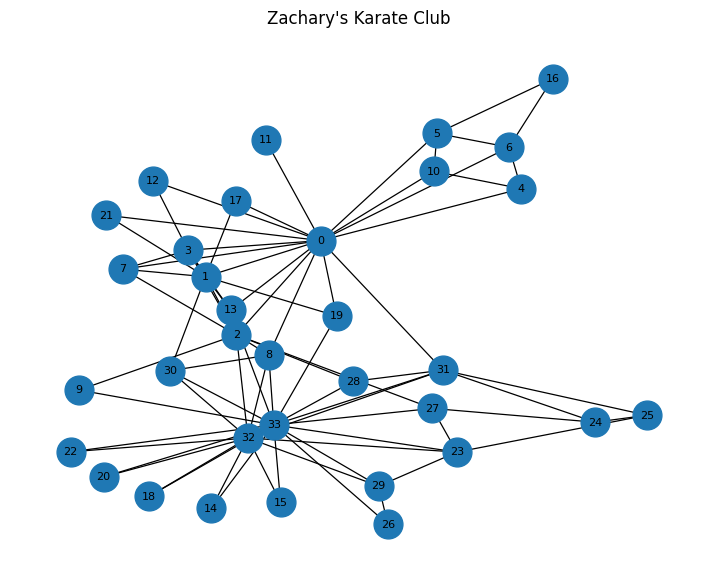

In [3]:
G = nx.karate_club_graph()
nodes = sorted(G.nodes())
A = nx.to_numpy_array(G, nodelist=nodes, weight=None, dtype=float)
validar_matriz(A)

n = G.number_of_nodes()
m_arestas = G.number_of_edges()
graus = A.sum(axis=1)
densidade = nx.density(G)
componentes = nx.number_connected_components(G)
rotulos_observados = np.array([
    0 if G.nodes[i]["club"] == "Mr. Hi" else 1 for i in nodes
], dtype=int)
pos = nx.spring_layout(G, seed=SEED, weight=None)

print(f"Vértices: {n}")
print(f"Arestas: {m_arestas}")
print(f"Densidade: {densidade:.6f}")
print(f"Componentes conexas: {componentes}")
print(f"Graus: min={graus.min():.0f}, média={graus.mean():.3f}, max={graus.max():.0f}")
print(f"Divisão observada: {np.bincount(rotulos_observados).tolist()}")

plt.figure(figsize=(9, 7))
nx.draw_networkx(G, pos=pos, with_labels=True, node_size=430, font_size=8, width=0.9)
plt.title("Zachary's Karate Club")
plt.axis("off")
salvar_figura("01_grafo_original.png")

A: (34, 34)
D: (34, 34)
L: (34, 34)
||L·1||₂ = 0.000e+00
||L-Lᵀ||F = 0.000e+00
λ1 = 0.000000000000
λ2 = 0.468525226701
Multiplicidade numérica de λ=0: 1
Componentes conexas: 1
Menores autovalores via eigsh: [0.         0.46852523 0.90924766 1.12501072]


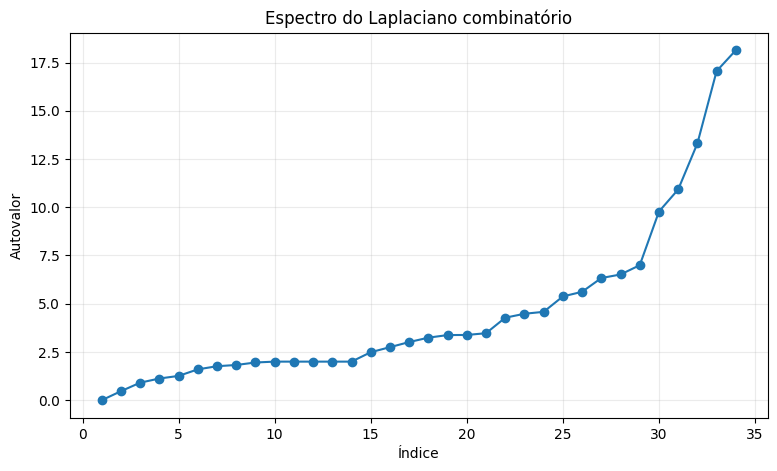

In [4]:
D, L, L_sym, L_rw, P = laplacianos(A)
erro_L1 = float(np.linalg.norm(L @ np.ones(n)))
simetria_L = float(np.linalg.norm(L - L.T))

print(f"A: {A.shape}")
print(f"D: {D.shape}")
print(f"L: {L.shape}")
print(f"||L·1||₂ = {erro_L1:.3e}")
print(f"||L-Lᵀ||F = {simetria_L:.3e}")

autovalores_L, autovetores_L = np.linalg.eigh(L)
tol_zero = 1e-10
multiplicidade_zero = int(np.sum(np.abs(autovalores_L) < tol_zero))
lambda1 = float(autovalores_L[0])
lambda2 = float(autovalores_L[1])
v2 = autovetores_L[:, 1]

L_sparse = csr_matrix(L)
valores_sparse, vetores_sparse = eigsh(L_sparse, k=4, which="SM")
ordem_sparse = np.argsort(valores_sparse)
valores_sparse = valores_sparse[ordem_sparse]

print(f"λ1 = {lambda1:.12f}")
print(f"λ2 = {lambda2:.12f}")
print(f"Multiplicidade numérica de λ=0: {multiplicidade_zero}")
print(f"Componentes conexas: {componentes}")
print("Menores autovalores via eigsh:", np.round(valores_sparse, 8))

plt.figure(figsize=(9, 5))
plt.plot(np.arange(1, n + 1), autovalores_L, marker="o")
plt.xlabel("Índice")
plt.ylabel("Autovalor")
plt.title("Espectro do Laplaciano combinatório")
plt.grid(alpha=0.25)
salvar_figura("02_espectro_laplaciano.png")

Threshold: 0.000000
Tamanhos: [15, 19]
Cut: 10.000000
RatioCut: 1.192982
Ncut: 0.262626


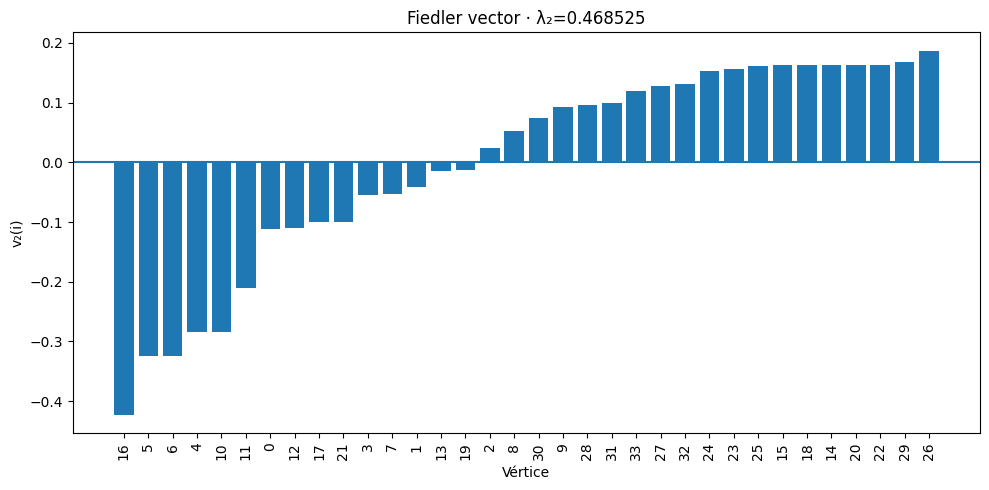

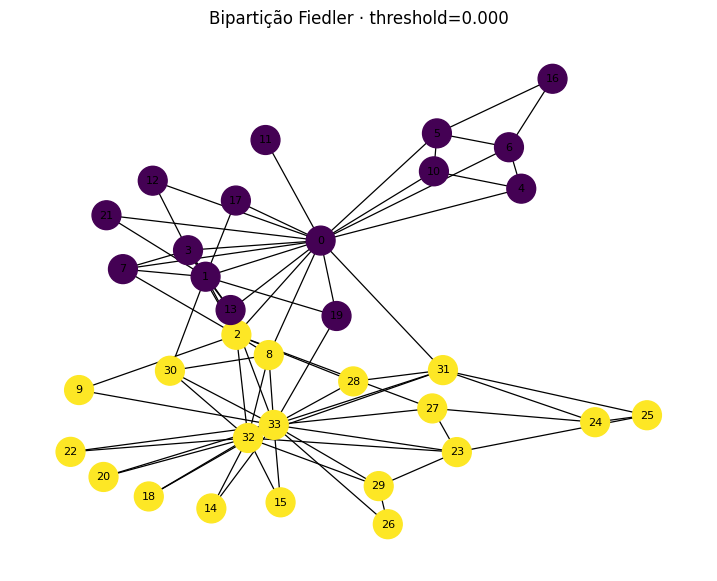

In [5]:
rotulos_fiedler = rotulos_threshold(v2, THRESHOLD)
cut_fiedler = valor_cut(A, rotulos_fiedler)
ratio_fiedler = ratio_cut(A, rotulos_fiedler)
ncut_fiedler = normalized_cut(A, rotulos_fiedler)

print(f"Threshold: {THRESHOLD:.6f}")
print(f"Tamanhos: {np.bincount(rotulos_fiedler).tolist()}")
print(f"Cut: {cut_fiedler:.6f}")
print(f"RatioCut: {ratio_fiedler:.6f}")
print(f"Ncut: {ncut_fiedler:.6f}")

plt.figure(figsize=(10, 5))
ordem = np.argsort(v2)
plt.bar(np.arange(n), v2[ordem])
plt.axhline(THRESHOLD, linewidth=1.5)
plt.xticks(np.arange(n), np.array(nodes)[ordem], rotation=90)
plt.xlabel("Vértice")
plt.ylabel("v₂(i)")
plt.title(f"Fiedler vector · λ₂={lambda2:.6f}")
plt.tight_layout()
salvar_figura("03_fiedler_values.png")

plt.figure(figsize=(9, 7))
nx.draw_networkx(
    G, pos=pos, with_labels=True, node_size=430, font_size=8,
    node_color=rotulos_fiedler, width=0.9
)
plt.title(f"Bipartição Fiedler · threshold={THRESHOLD:.3f}")
plt.axis("off")
salvar_figura("04_biparticao_fiedler.png")

Melhor cut: {'threshold': -0.3732462737696851, 'cut': 2.0, 'ratiocut': 2.0606060606060606, 'ncut': 1.0129870129870129, 'n0': 1, 'n1': 33}
Melhor RatioCut: {'threshold': -0.2477987395014087, 'cut': 4.0, 'ratiocut': 0.9379310344827587, 'ncut': 0.2785714285714286, 'n0': 5, 'n1': 29}
Melhor Ncut: {'threshold': 0.03741011585482685, 'cut': 10.0, 'ratiocut': 1.1805555555555556, 'ncut': 0.2565789473684211, 'n0': 16, 'n1': 18}


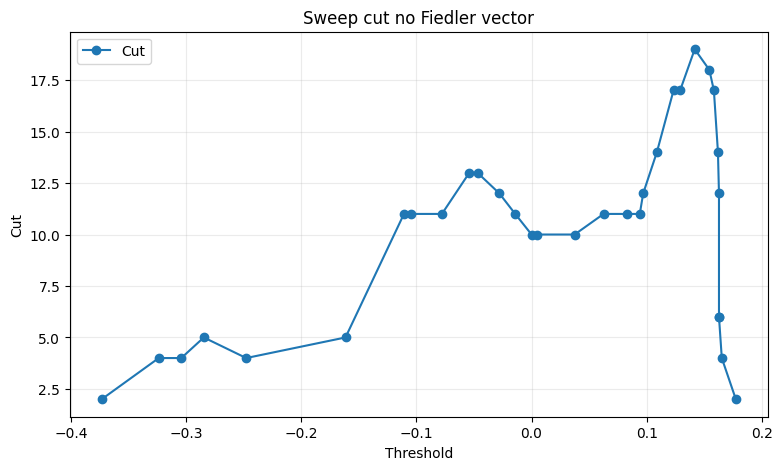

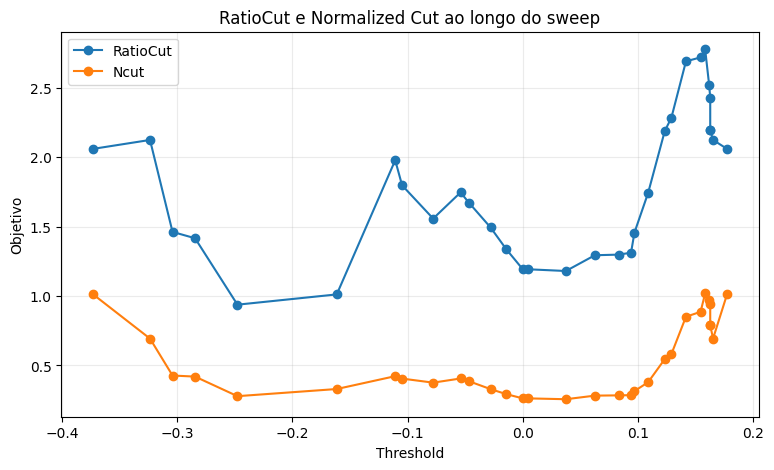

In [6]:
sweep = sweep_fiedler(A, v2)
melhor_cut = min(sweep, key=lambda x: x["cut"])
melhor_ratio = min(sweep, key=lambda x: x["ratiocut"])
melhor_ncut = min(sweep, key=lambda x: x["ncut"])

print("Melhor cut:", melhor_cut)
print("Melhor RatioCut:", melhor_ratio)
print("Melhor Ncut:", melhor_ncut)

thresholds = np.array([x["threshold"] for x in sweep])
cuts = np.array([x["cut"] for x in sweep])
ratios = np.array([x["ratiocut"] for x in sweep])
ncuts = np.array([x["ncut"] for x in sweep])

plt.figure(figsize=(9, 5))
plt.plot(thresholds, cuts, marker="o", label="Cut")
plt.xlabel("Threshold")
plt.ylabel("Cut")
plt.title("Sweep cut no Fiedler vector")
plt.grid(alpha=0.25)
plt.legend()
salvar_figura("05_sweep_cut.png")

plt.figure(figsize=(9, 5))
plt.plot(thresholds, ratios, marker="o", label="RatioCut")
plt.plot(thresholds, ncuts, marker="o", label="Ncut")
plt.xlabel("Threshold")
plt.ylabel("Objetivo")
plt.title("RatioCut e Normalized Cut ao longo do sweep")
plt.grid(alpha=0.25)
plt.legend()
salvar_figura("06_ratiocut_ncut.png")

||L_rw-(I-P)||F = 0.000e+00
max |eig(L_sym)-eig(L_rw)| = 2.220e-15


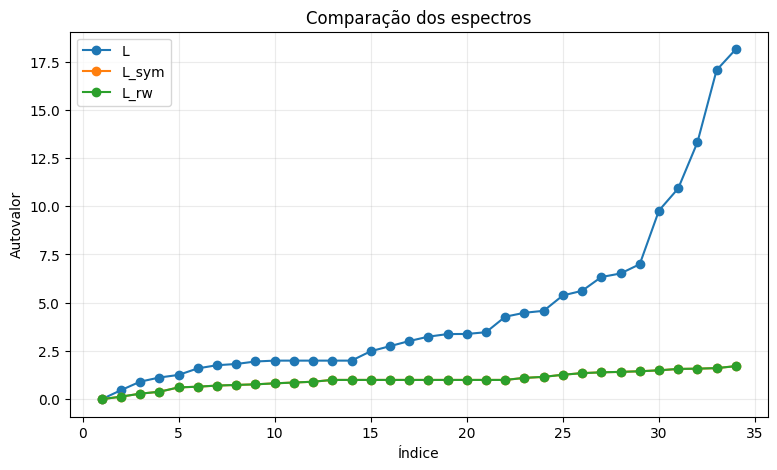

In [7]:
autovalores_Lsym = np.linalg.eigvalsh(L_sym)
autovalores_Lrw = np.sort(np.linalg.eigvals(L_rw).real)
erro_rw = float(np.linalg.norm(L_rw - (np.eye(n) - P)))
erro_espectros_normalizados = float(np.max(np.abs(autovalores_Lsym - autovalores_Lrw)))

print(f"||L_rw-(I-P)||F = {erro_rw:.3e}")
print(f"max |eig(L_sym)-eig(L_rw)| = {erro_espectros_normalizados:.3e}")

plt.figure(figsize=(9, 5))
plt.plot(np.arange(1, n + 1), autovalores_L, marker="o", label="L")
plt.plot(np.arange(1, n + 1), autovalores_Lsym, marker="o", label="L_sym")
plt.plot(np.arange(1, n + 1), autovalores_Lrw, marker="o", label="L_rw")
plt.xlabel("Índice")
plt.ylabel("Autovalor")
plt.title("Comparação dos espectros")
plt.grid(alpha=0.25)
plt.legend()
salvar_figura("07_espectros_laplacianos.png")

Caminho (25 passos):
[0, 2, 27, 24, 27, 23, 33, 9, 33, 14, 32, 22, 33, 29, 33, 29, 33, 23, 25, 31, 25, 24, 27, 2, 32, 30]


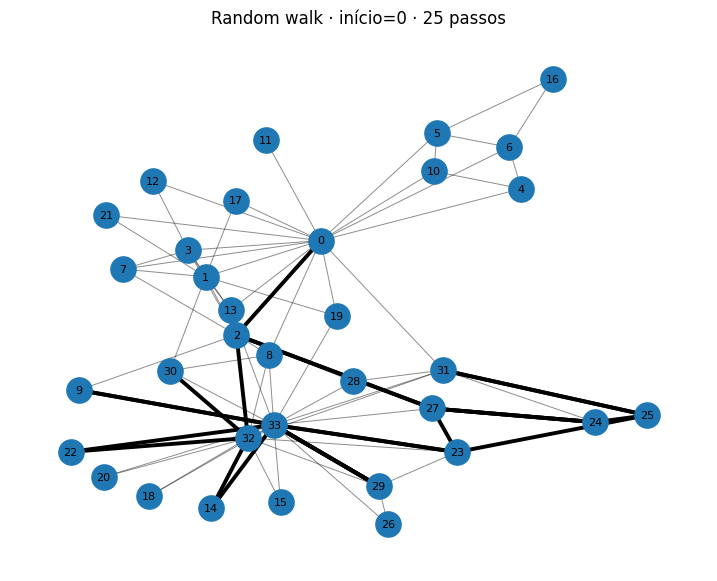

In [8]:
caminho_rw = random_walk(G, inicio=0, passos=RANDOM_WALK_STEPS, seed=SEED)
arestas_rw = list(zip(caminho_rw[:-1], caminho_rw[1:]))

print(f"Caminho ({len(caminho_rw)-1} passos):")
print(caminho_rw)

plt.figure(figsize=(9, 7))
nx.draw_networkx_edges(G, pos=pos, width=0.7, alpha=0.45)
nx.draw_networkx_nodes(G, pos=pos, node_size=330)
nx.draw_networkx_labels(G, pos=pos, font_size=8)
nx.draw_networkx_edges(G, pos=pos, edgelist=arestas_rw, width=2.8)
plt.title(f"Random walk · início=0 · {RANDOM_WALK_STEPS} passos")
plt.axis("off")
salvar_figura("08_random_walk.png")

k spectral: 2
Tamanhos: [15, 19]


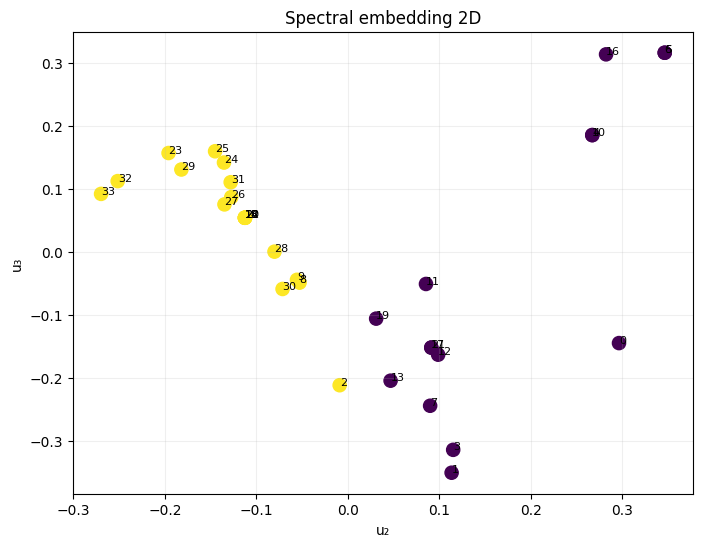

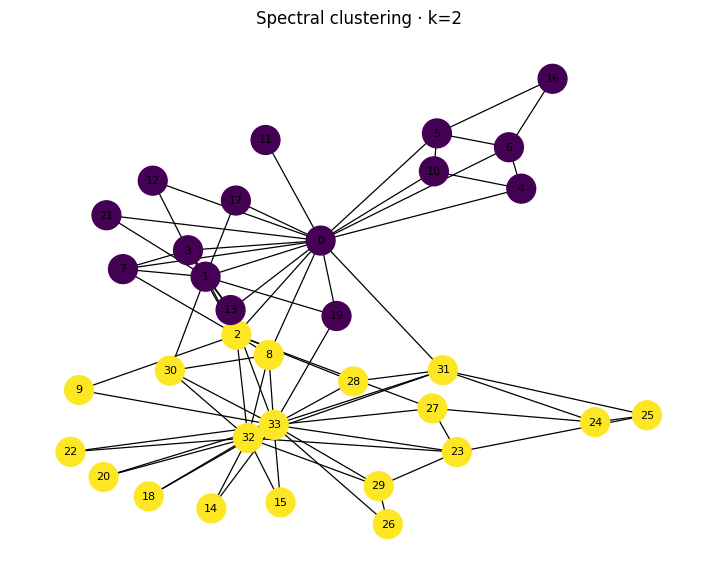

In [9]:
rotulos_spectral, embedding_k, espectro_sym = spectral_clustering(A, K_SPECTRAL, SEED)

_, vetores_sym = np.linalg.eigh(L_sym)
embedding_2d = vetores_sym[:, 1:3]

print(f"k spectral: {K_SPECTRAL}")
print(f"Tamanhos: {np.bincount(rotulos_spectral).tolist()}")

plt.figure(figsize=(8, 6))
plt.scatter(embedding_2d[:, 0], embedding_2d[:, 1], c=rotulos_spectral, s=90)
for i, no in enumerate(nodes):
    plt.text(embedding_2d[i, 0], embedding_2d[i, 1], str(no), fontsize=8)
plt.xlabel("u₂")
plt.ylabel("u₃")
plt.title("Spectral embedding 2D")
plt.grid(alpha=0.2)
salvar_figura("09_spectral_embedding.png")

plt.figure(figsize=(9, 7))
nx.draw_networkx(
    G, pos=pos, with_labels=True, node_size=430, font_size=8,
    node_color=rotulos_spectral, width=0.9
)
plt.title(f"Spectral clustering · k={K_SPECTRAL}")
plt.axis("off")
salvar_figura("10_spectral_clustering.png")

Menores autovalores de L_sym: [-0.        0.132272  0.287049  0.387313  0.612231  0.648993  0.707208
  0.739958  0.770911  0.822943  0.864833]
Eigengaps: [0.132272 0.154777 0.100264 0.224917 0.036762 0.058215 0.03275  0.030953
 0.052032 0.04189 ]
k sugerido pelo maior eigengap no intervalo analisado: 4


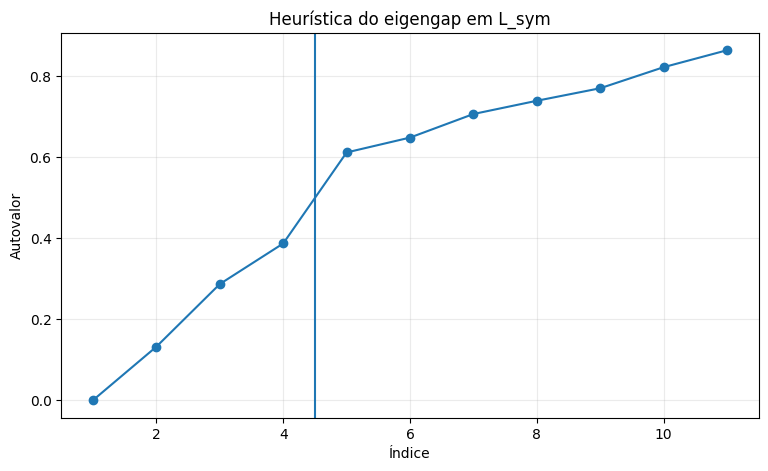

In [10]:
limite = min(K_EIGENGAP_MAX, n - 1)
gaps = np.diff(autovalores_Lsym[:limite + 1])
k_eigengap = int(np.argmax(gaps) + 1)

print("Menores autovalores de L_sym:", np.round(autovalores_Lsym[:limite + 1], 6))
print("Eigengaps:", np.round(gaps, 6))
print(f"k sugerido pelo maior eigengap no intervalo analisado: {k_eigengap}")

plt.figure(figsize=(9, 5))
plt.plot(np.arange(1, limite + 2), autovalores_Lsym[:limite + 1], marker="o")
plt.axvline(k_eigengap + 0.5, linewidth=1.5)
plt.xlabel("Índice")
plt.ylabel("Autovalor")
plt.title("Heurística do eigengap em L_sym")
plt.grid(alpha=0.25)
salvar_figura("11_eigengap.png")

m = 78
||B·1||₂ = 1.699e-15
||B-Bᵀ||F = 0.000e+00
Σij B_ij = -3.775e-15
λ_max(B) = 4.977080225730
Tamanhos Newman: [18, 16]


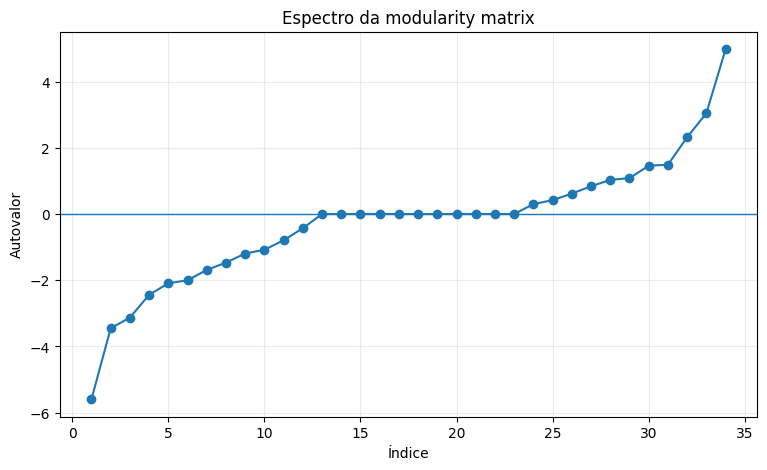

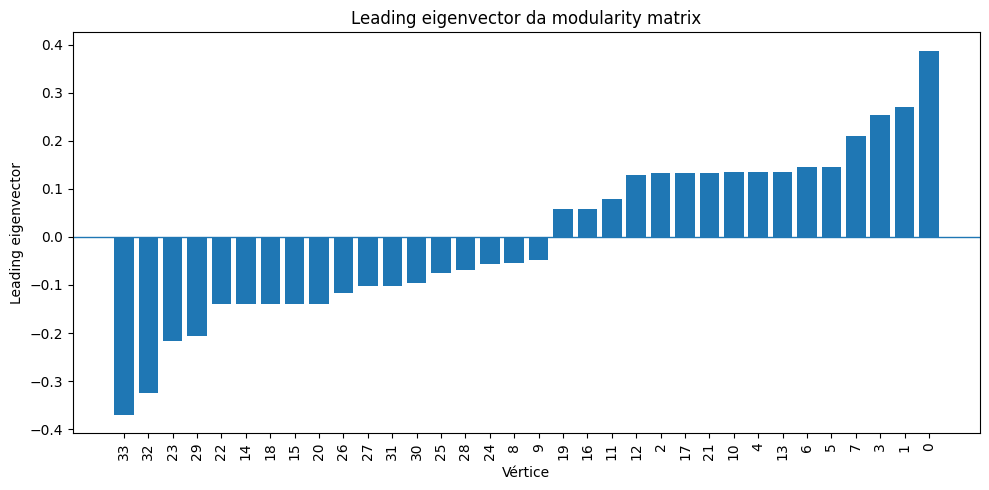

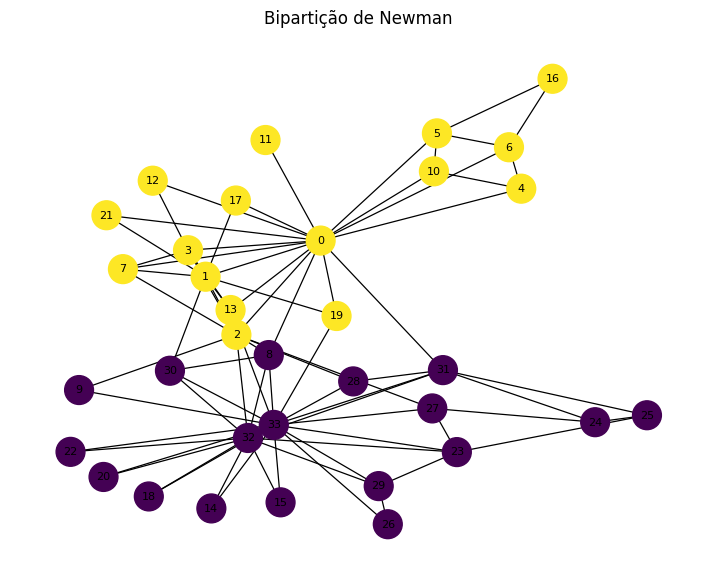

In [11]:
B, k_vec, m = modularity_matrix(A)
erro_B1 = float(np.linalg.norm(B @ np.ones(n)))
erro_simetria_B = float(np.linalg.norm(B - B.T))
soma_B = float(B.sum())

rotulos_newman, autovalores_B, leading = newman_leading(A)
lambda_max_B = float(np.max(autovalores_B))

print(f"m = {m:.0f}")
print(f"||B·1||₂ = {erro_B1:.3e}")
print(f"||B-Bᵀ||F = {erro_simetria_B:.3e}")
print(f"Σij B_ij = {soma_B:.3e}")
print(f"λ_max(B) = {lambda_max_B:.12f}")
print(f"Tamanhos Newman: {np.bincount(rotulos_newman).tolist()}")

plt.figure(figsize=(9, 5))
plt.plot(np.arange(1, n + 1), autovalores_B, marker="o")
plt.axhline(0.0, linewidth=1.0)
plt.xlabel("Índice")
plt.ylabel("Autovalor")
plt.title("Espectro da modularity matrix")
plt.grid(alpha=0.25)
salvar_figura("12_espectro_modularity_matrix.png")

plt.figure(figsize=(10, 5))
ordem_B = np.argsort(leading)
plt.bar(np.arange(n), leading[ordem_B])
plt.axhline(0.0, linewidth=1.0)
plt.xticks(np.arange(n), np.array(nodes)[ordem_B], rotation=90)
plt.xlabel("Vértice")
plt.ylabel("Leading eigenvector")
plt.title("Leading eigenvector da modularity matrix")
plt.tight_layout()
salvar_figura("13_leading_eigenvector.png")

plt.figure(figsize=(9, 7))
nx.draw_networkx(
    G, pos=pos, with_labels=True, node_size=430, font_size=8,
    node_color=rotulos_newman, width=0.9
)
plt.title("Bipartição de Newman")
plt.axis("off")
salvar_figura("14_particao_newman.png")

Comunidades recursivas: 4
Tamanhos: [7, 9, 12, 6]
Q recursivo = 0.393408941486
Ganhos aceitos:
1 {'delta_Q': 0.3714661406969099, 'lambda_max': 4.977080225729889, 'tamanho_1': 16, 'tamanho_2': 18}
2 {'delta_Q': 0.001232741617356999, 'lambda_max': 1.1785377166236142, 'tamanho_1': 7, 'tamanho_2': 9}
3 {'delta_Q': 0.02071005917159763, 'lambda_max': 0.8594147207778123, 'tamanho_1': 12, 'tamanho_2': 6}


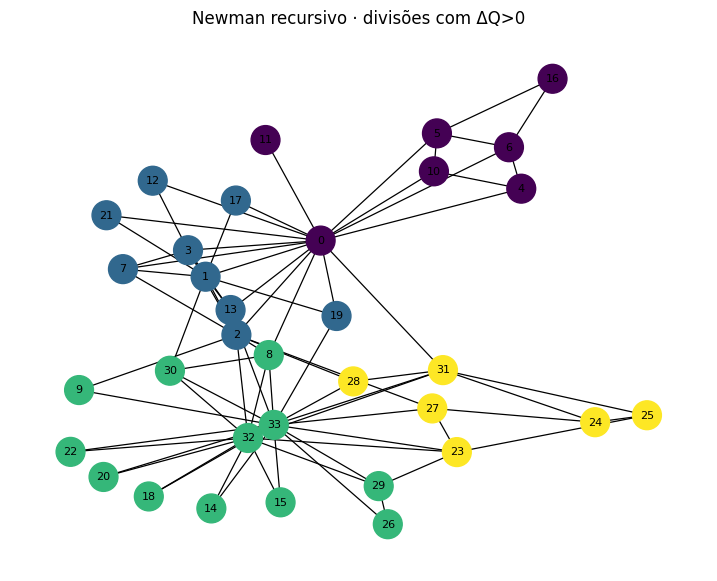

In [12]:
rotulos_newman_rec, comunidades_newman_rec, ganhos_newman_rec = newman_recursivo(A)
q_newman_rec = modularidade(G, rotulos_newman_rec)

print(f"Comunidades recursivas: {len(comunidades_newman_rec)}")
print("Tamanhos:", [len(c) for c in comunidades_newman_rec])
print(f"Q recursivo = {q_newman_rec:.12f}")
print("Ganhos aceitos:")
for i, ganho in enumerate(ganhos_newman_rec, start=1):
    print(i, ganho)

plt.figure(figsize=(9, 7))
nx.draw_networkx(
    G, pos=pos, with_labels=True, node_size=430, font_size=8,
    node_color=rotulos_newman_rec, width=0.9
)
plt.title("Newman recursivo · divisões com ΔQ>0")
plt.axis("off")
salvar_figura("15_newman_recursivo.png")

Método                  Grupos          Q        ARI        NMI
---------------------------------------------------------------
Observado                    2   0.358235   1.000000   1.000000
Fiedler sinal                2   0.359961   0.771725   0.732378
Fiedler RatioCut             2   0.132807   0.072402   0.206487
Fiedler Ncut                 2   0.371466   0.882258   0.837169
Spectral k=2                 2   0.359961   0.771725   0.732378
Newman leading               2   0.371466   0.882258   0.837169
Newman recursivo             4   0.393409   0.435155   0.579157


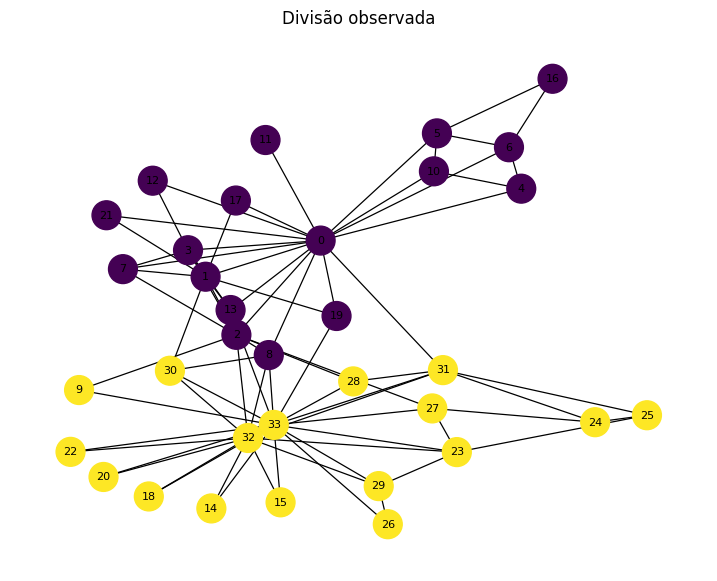

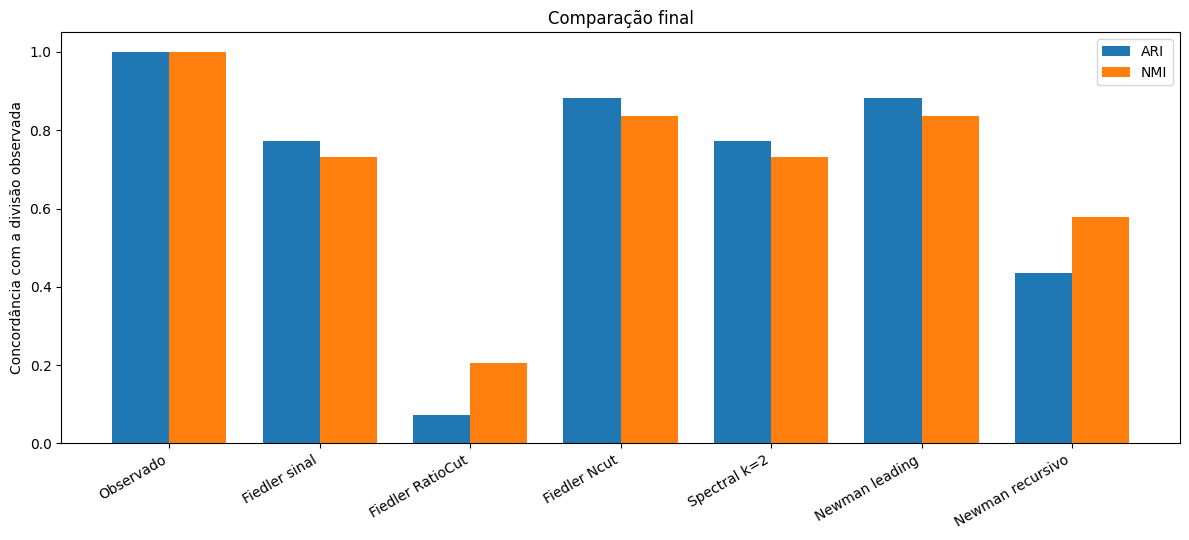

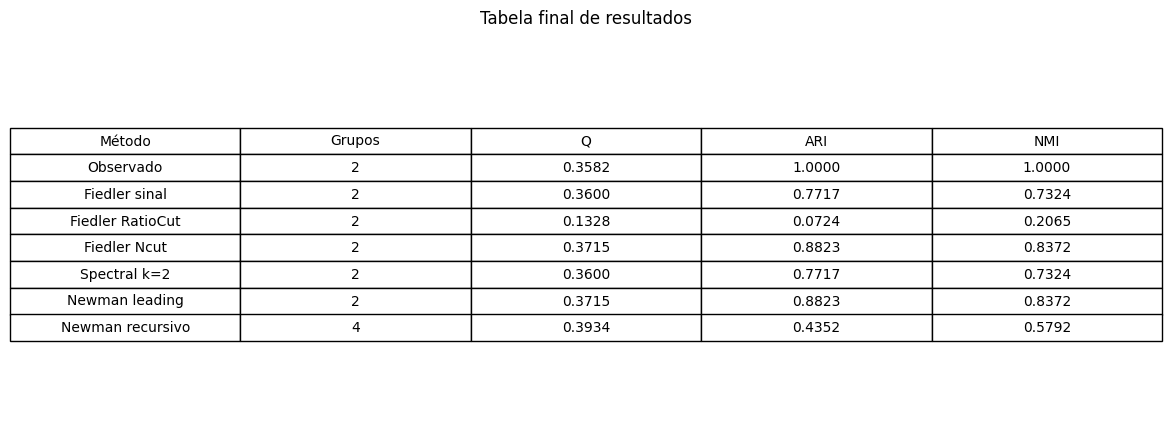

In [13]:
rotulos_ratio = rotulos_threshold(v2, melhor_ratio["threshold"])
rotulos_ncut = rotulos_threshold(v2, melhor_ncut["threshold"])

metodos = {
    "Observado": rotulos_observados,
    "Fiedler sinal": rotulos_fiedler,
    "Fiedler RatioCut": rotulos_ratio,
    "Fiedler Ncut": rotulos_ncut,
    f"Spectral k={K_SPECTRAL}": rotulos_spectral,
    "Newman leading": rotulos_newman,
    "Newman recursivo": rotulos_newman_rec
}

resultados = []
for nome, rotulos in metodos.items():
    ari, nmi = metricas_externas(rotulos_observados, rotulos)
    resultados.append({
        "Método": nome,
        "Grupos": int(len(np.unique(rotulos))),
        "Q": modularidade(G, rotulos),
        "ARI": ari,
        "NMI": nmi
    })

cabecalho = f"{'Método':<22} {'Grupos':>7} {'Q':>10} {'ARI':>10} {'NMI':>10}"
print(cabecalho)
print("-" * len(cabecalho))
for r in resultados:
    print(f"{r['Método']:<22} {r['Grupos']:>7d} {r['Q']:>10.6f} {r['ARI']:>10.6f} {r['NMI']:>10.6f}")

plt.figure(figsize=(9, 7))
nx.draw_networkx(
    G, pos=pos, with_labels=True, node_size=430, font_size=8,
    node_color=rotulos_observados, width=0.9
)
plt.title("Divisão observada")
plt.axis("off")
salvar_figura("16_divisao_observada.png")

nomes = [r["Método"] for r in resultados]
ari_vals = [r["ARI"] for r in resultados]
nmi_vals = [r["NMI"] for r in resultados]
x = np.arange(len(nomes))
largura = 0.38

plt.figure(figsize=(12, 5.5))
plt.bar(x - largura / 2, ari_vals, width=largura, label="ARI")
plt.bar(x + largura / 2, nmi_vals, width=largura, label="NMI")
plt.xticks(x, nomes, rotation=30, ha="right")
plt.ylim(0, 1.05)
plt.ylabel("Concordância com a divisão observada")
plt.title("Comparação final")
plt.legend()
plt.tight_layout()
salvar_figura("17_comparacao_final.png")

fig = plt.figure(figsize=(12, 4.5))
ax = fig.add_axes([0.02, 0.05, 0.96, 0.9])
ax.axis("off")
dados_tabela = [[
    r["Método"], r["Grupos"], f"{r['Q']:.4f}", f"{r['ARI']:.4f}", f"{r['NMI']:.4f}"
] for r in resultados]
tabela = ax.table(
    cellText=dados_tabela,
    colLabels=["Método", "Grupos", "Q", "ARI", "NMI"],
    loc="center",
    cellLoc="center"
)
tabela.auto_set_font_size(False)
tabela.set_fontsize(10)
tabela.scale(1, 1.6)
plt.title("Tabela final de resultados")
salvar_figura("18_tabela_final.png")

In [14]:
print()
print("RESUMO FINAL")
print(f"n={n}, m={m_arestas}, componentes={componentes}")
print(f"||L·1||₂={erro_L1:.3e}")
print(f"λ1={lambda1:.12f}")
print(f"λ2={lambda2:.12f}")
print(f"Fiedler sinal: grupos={np.bincount(rotulos_fiedler).tolist()}, Q={modularidade(G, rotulos_fiedler):.6f}")
print(f"Melhor RatioCut: threshold={melhor_ratio['threshold']:.6f}, valor={melhor_ratio['ratiocut']:.6f}")
print(f"Melhor Ncut: threshold={melhor_ncut['threshold']:.6f}, valor={melhor_ncut['ncut']:.6f}")
print(f"Eigengap em L_sym sugere k={k_eigengap} no intervalo 1..{limite}")
print(f"λmax(B)={lambda_max_B:.12f}")
print(f"Newman leading: grupos={np.bincount(rotulos_newman).tolist()}, Q={modularidade(G, rotulos_newman):.6f}")
print(f"Newman recursivo: comunidades={len(comunidades_newman_rec)}, Q={q_newman_rec:.6f}")
print(f"Figuras salvas em: {OUTPUTS.resolve()}")


RESUMO FINAL
n=34, m=78, componentes=1
||L·1||₂=0.000e+00
λ1=0.000000000000
λ2=0.468525226701
Fiedler sinal: grupos=[15, 19], Q=0.359961
Melhor RatioCut: threshold=-0.247799, valor=0.937931
Melhor Ncut: threshold=0.037410, valor=0.256579
Eigengap em L_sym sugere k=4 no intervalo 1..10
λmax(B)=4.977080225730
Newman leading: grupos=[18, 16], Q=0.371466
Newman recursivo: comunidades=4, Q=0.393409
Figuras salvas em: C:\Users\HP\3D Objects\USP ICMC\PRIMERO\Redes Complexas para Ciência da Computação\seminario\outputs
